Loading Shapefile: D:\MANGROVES\Research_Article_Clean\Created_Data\gmwv4_mask_anthropogenic_validation.shp ...
Anthropogenic mask applied: 435 tiles excluded. Remaining: 1261 valid tiles.
Loading SSH and Mangrove datasets...


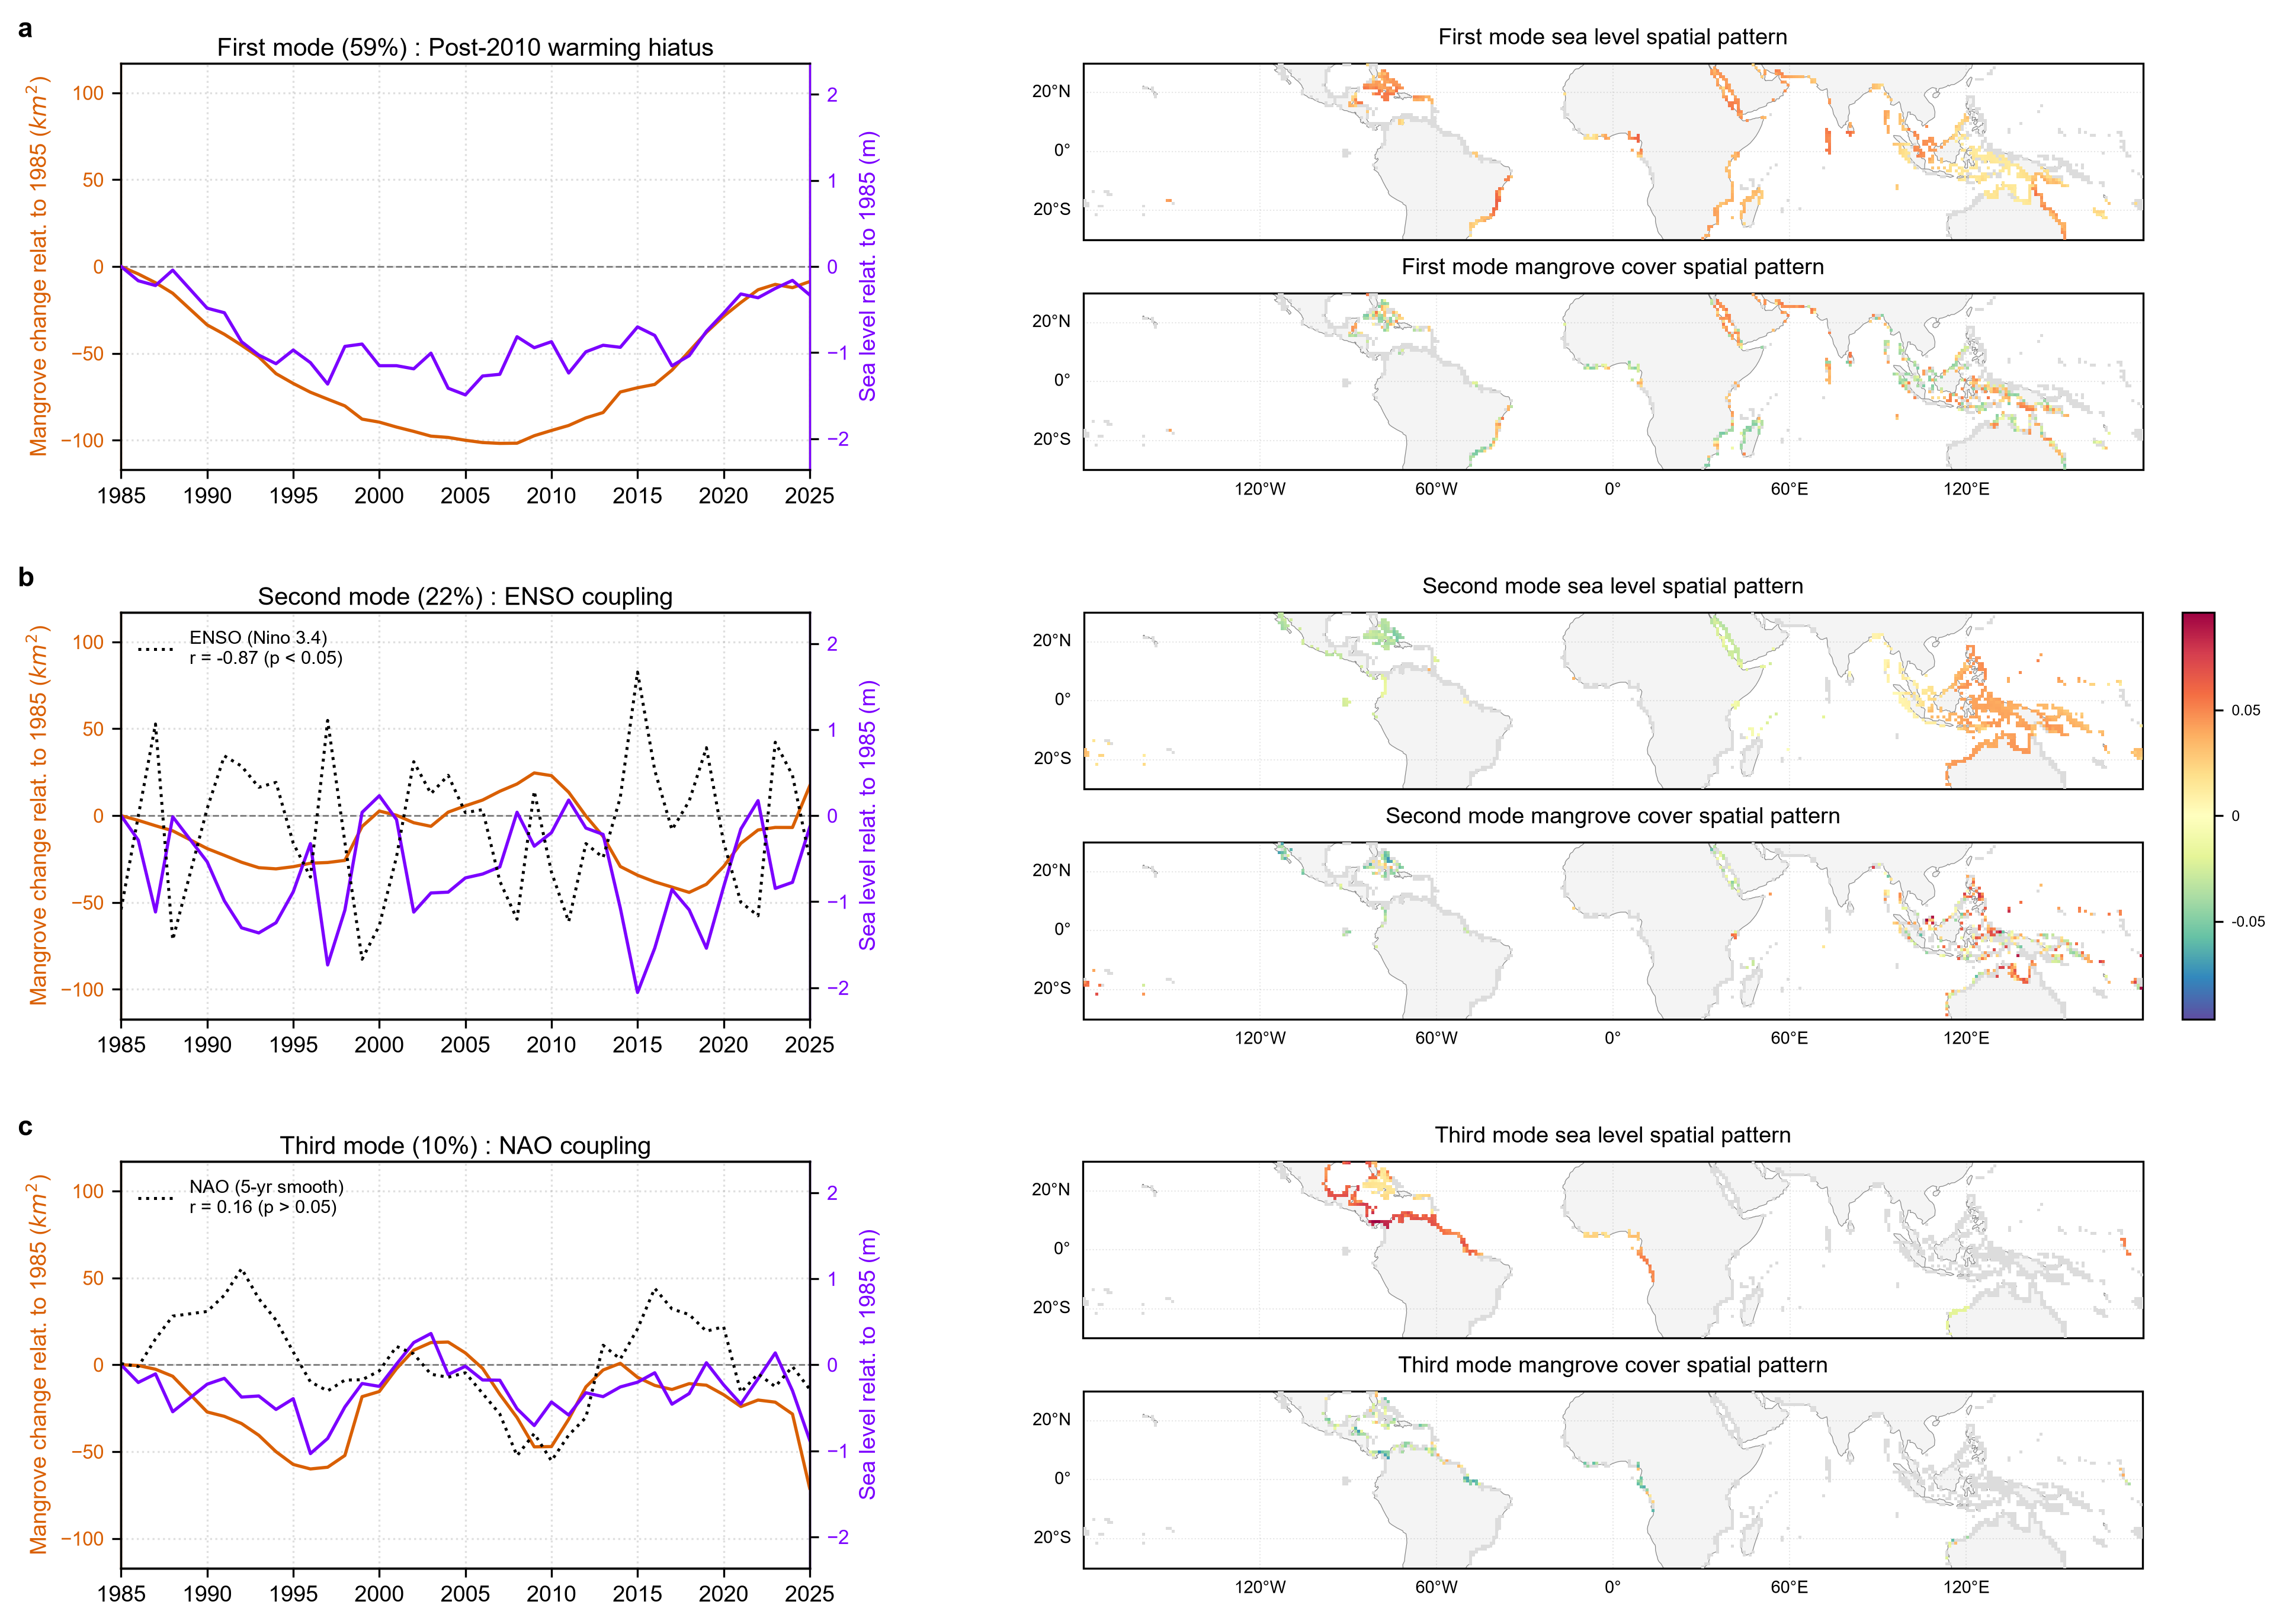


Figure successfully generated: D:\MANGROVES\Research_Article_Clean\Figure4\Figure4.tif

Exporting results...
Spatial results exported to GPKG: D:\MANGROVES\Research_Article_Clean\Figure4\mca_spatial_results_validated.gpkg
SSH time series exported: D:\MANGROVES\Research_Article_Clean\Figure4\ssh_pcs_modes1_3.csv
Mangrove time series exported: D:\MANGROVES\Research_Article_Clean\Figure4\mangrove_pcs_modes1_3.csv


In [9]:
"""
================================================================================
SCRIPT NAME: Figure 4 (Fixed Map Titles via ax.text)

AUTHOR: R. Walcker, CRBE
================================================================================
"""

from pathlib import Path
import warnings
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from scipy import stats

# Suppress non-critical warnings
warnings.filterwarnings("ignore")

# ==========================================
# 1. DIRECTORIES AND CONFIGURATION (NATURE STYLE)
# ==========================================
OUT_DIR = Path(r"D:\MANGROVES\Research_Article_Clean\Figure4")
OUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_MSL_ANNUAL = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\ecmwf_msl_annual_1deg_tiles.csv")
CSV_MANGROVE = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\gmwv4_surfaces_annual_1deg_tiles.csv")
SHP_PATH = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\gmwv4_mask_anthropogenic_validation.shp")
NINO34_URL = "https://psl.noaa.gov/data/correlation/nina34.data"
NAO_URL = "https://psl.noaa.gov/data/correlation/nao.data"

if not CSV_MSL_ANNUAL.exists():
    raise FileNotFoundError(f"CSV SSH file not found: {CSV_MSL_ANNUAL}")
if not CSV_MANGROVE.exists():
    raise FileNotFoundError(f"CSV Mangrove file not found: {CSV_MANGROVE}")
if not SHP_PATH.exists():
    raise FileNotFoundError(f"Shapefile not found: {SHP_PATH}")

COLOR_MANGROVE = "#d95f02"
COLOR_SSH_MEAN = "#7b00ff"
SMOOTH_WINDOW = 5

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "mathtext.fontset": "dejavusans",
    "axes.linewidth": 0.8,
    "font.size": 9.5,
    "axes.labelsize": 9.5,
    "axes.titlesize": 10.5,
    "xtick.labelsize": 9.0,
    "ytick.labelsize": 9.0,
})

# ==========================================
# 2. LOADING DATASETS & SHAPEFILE
# ==========================================
print(f"Loading Shapefile: {SHP_PATH} ...")
gdf_tiles_raw = gpd.read_file(SHP_PATH)
if "tile_id" not in gdf_tiles_raw.columns:
    tile_col = "clean_id" if "clean_id" in gdf_tiles_raw.columns else gdf_tiles_raw.columns[0]
    gdf_tiles_raw["tile_id"] = gdf_tiles_raw[tile_col].astype(str).str.strip()
else:
    gdf_tiles_raw["tile_id"] = gdf_tiles_raw["tile_id"].astype(str).str.strip()

if "mask_artif" in gdf_tiles_raw.columns:
    n_before = len(gdf_tiles_raw)
    gdf_tiles = gdf_tiles_raw[gdf_tiles_raw["mask_artif"] != 1].copy()
    print(f"Anthropogenic mask applied: {n_before - len(gdf_tiles)} tiles excluded. Remaining: {len(gdf_tiles)} valid tiles.")
else:
    gdf_tiles = gdf_tiles_raw.copy()

print("Loading SSH and Mangrove datasets...")
df_ssh_raw = pd.read_csv(CSV_MSL_ANNUAL, sep=None, engine='python')
df_ssh_raw.columns = [str(c).strip() for c in df_ssh_raw.columns]
if 'tile_id' not in df_ssh_raw.columns:
    possible_id = next((c for c in ['clean_id', 'ID', 'id'] if c in df_ssh_raw.columns), df_ssh_raw.columns[0])
    df_ssh_raw = df_ssh_raw.rename(columns={possible_id: 'tile_id'})
df_ssh_raw['tile_id'] = df_ssh_raw['tile_id'].astype(str).str.strip()
df_ssh_raw['year'] = pd.to_numeric(df_ssh_raw['year'], errors='coerce')
df_ssh_raw['SSH_m'] = pd.to_numeric(df_ssh_raw['SSH_m'], errors='coerce')
df_ssh_raw = df_ssh_raw.dropna(subset=['year', 'SSH_m'])
df_ssh_raw['year'] = df_ssh_raw['year'].astype(int)
df_ssh_data = df_ssh_raw.pivot(index='year', columns='tile_id', values='SSH_m').sort_index(ascending=True)

df_mg_raw = pd.read_csv(CSV_MANGROVE, sep=None, engine='python')
df_mg_raw.columns = [str(c).strip() for c in df_mg_raw.columns]
df_mg_raw['tile_id'] = df_mg_raw['tile_id'].astype(str).str.strip()
df_mg_raw['year'] = pd.to_numeric(df_mg_raw['year'], errors='coerce')
df_mg_raw = df_mg_raw.dropna(subset=['year'])
df_mg_raw['year'] = df_mg_raw['year'].astype(int)
df_mg_data = df_mg_raw.pivot(index='year', columns='tile_id', values='area_km2').sort_index(ascending=True)

common_years = np.intersect1d(df_ssh_data.index.values, df_mg_data.index.values)
all_ssh_tiles = [str(t).strip() for t in df_ssh_data.columns.values]
all_mg_tiles = [str(t).strip() for t in df_mg_data.columns.values]
shape_tiles = [str(t).strip() for t in gdf_tiles["tile_id"].values]

common_tiles = np.intersect1d(np.intersect1d(all_ssh_tiles, all_mg_tiles), shape_tiles)
df_ssh = df_ssh_data.loc[common_years, common_tiles]
df_mg = df_mg_data.loc[common_years, common_tiles]
years = common_years
tile_ids = common_tiles

# ==========================================
# 3. DOWNLOADING AND PROCESSING CLIMATE INDICES
# ==========================================
nino_df = pd.read_csv(NINO34_URL, skiprows=1, header=None, sep=r"\s+").dropna(how="all").iloc[:, :13]
nino_df.columns = ["Year"] + [f"M{m}" for m in range(1, 13)]
nino_df["Year"] = pd.to_numeric(nino_df["Year"], errors="coerce")
nino_df = nino_df.dropna(subset=["Year"]).astype({"Year": int}).set_index("Year")
for col in nino_df.columns:
    nino_df[col] = pd.to_numeric(nino_df[col], errors="coerce")
nino_annual = nino_df.replace([-99.99, -999.0, 99.99], np.nan).mean(axis=1)
nino_aligned = nino_annual.reindex(years)

nao_df = pd.read_csv(NAO_URL, skiprows=1, header=None, sep=r"\s+").dropna(how="all").iloc[:, :13]
nao_df.columns = ["Year"] + [f"M{m}" for m in range(1, 13)]
nao_df["Year"] = pd.to_numeric(nao_df["Year"], errors="coerce")
nao_df = nao_df.dropna(subset=["Year"]).astype({"Year": int}).set_index("Year")
for col in nao_df.columns:
    nao_df[col] = pd.to_numeric(nao_df[col], errors="coerce")
nao_annual = nao_df.replace([-99.99, -999.0, 99.99], np.nan).mean(axis=1)
nao_aligned = nao_annual.reindex(years)

nino_plot_vals = nino_aligned.values
nao_plot_vals = nao_aligned.rolling(window=SMOOTH_WINDOW, center=True, min_periods=1).mean().values

nino_ylim = (np.nanmin(nino_plot_vals) - 0.5, np.nanmax(nino_plot_vals) + 0.5)
nao_ylim = (np.nanmin(nao_plot_vals) - 0.5, np.nanmax(nao_plot_vals) + 0.5)

# ==========================================
# 4. POINT-BY-POINT DETRENDING & MCA SVD
# ==========================================
def get_detrended_stats(df):
    data_mat = df.values
    slopes, intercepts = np.polyfit(years, data_mat, 1)
    trend_mat = np.outer(years, slopes) + intercepts
    detrended = data_mat - trend_mat
    df_det = pd.DataFrame(detrended, index=years, columns=df.columns)
    means = df_det.mean(axis=0)
    stds = df_det.std(axis=0, ddof=0).fillna(1.0).replace(0, 1.0)
    zscored = ((df_det - means) / stds).fillna(0)
    return zscored.values, stds, df_det

X, ssh_stds, df_ssh_det = get_detrended_stats(df_ssh)
Y, mg_stds, df_mg_det = get_detrended_stats(df_mg)

mean_std_ssh_m = ssh_stds.mean()
mean_std_mg_km2 = mg_stds.mean()

n_samples = X.shape[0]
C_xy = np.dot(X.T, Y) / (n_samples - 1)
U, S, Vt = np.linalg.svd(C_xy, full_matrices=False)
V = Vt.T
cov_fraction = ((S ** 2) / np.sum(S ** 2)) * 100.0

A_raw = np.dot(X, U)
B_raw = np.dot(Y, V)
n_modes = min(3, len(S))

for m in range(n_modes):
    if np.sum(A_raw[:, m]) < 0:
        A_raw[:, m] = -A_raw[:, m]
        U[:, m] = -U[:, m]
    if np.sum(B_raw[:, m]) < 0:
        B_raw[:, m] = -B_raw[:, m]
        V[:, m] = -V[:, m]
    if np.corrcoef(A_raw[:, m], B_raw[:, m])[0, 1] < 0:
        B_raw[:, m] = -B_raw[:, m]
        V[:, m] = -V[:, m]

A = np.zeros_like(A_raw)
B = np.zeros_like(B_raw)
for m in range(n_modes):
    a_m = A_raw[:, m] * mean_std_ssh_m
    A[:, m] = a_m - a_m[0]
    b_km2 = B_raw[:, m] * mean_std_mg_km2
    B[:, m] = b_km2 - b_km2[0]

# Align Mode 2 positively with ENSO
A[:, 1] = -A[:, 1]
B[:, 1] = -B[:, 1]
U[:, 1] = -U[:, 1]
V[:, 1] = -V[:, 1]

global_y_max_ssh = np.max(np.abs(A[:, :3])) * 1.15
global_y_max_mg = np.max(np.abs(B[:, :3])) * 1.15

valid_idx_nino = ~np.isnan(nino_aligned.values) & ~np.isnan(A[:, 1])
r_nino, p_nino = stats.pearsonr(nino_aligned.values[valid_idx_nino], A[:, 1][valid_idx_nino])

A_ssh_smooth_mode3 = pd.Series(A[:, 2]).rolling(window=SMOOTH_WINDOW, center=True, min_periods=1).mean().values
valid_idx_nao = ~np.isnan(nao_aligned.values) & ~np.isnan(A_ssh_smooth_mode3)
r_nao, p_nao = stats.pearsonr(nao_aligned.values[valid_idx_nao], A_ssh_smooth_mode3[valid_idx_nao])

# ==========================================
# 5. SIGNIFICANCE TESTING & MAPPING PREPARATION
# ==========================================
mca_dict = {"tile_id": list(tile_ids)}
for m in range(n_modes):
    mca_dict[f"SSH_MCA{m+1}"] = U[:, m]
    mca_dict[f"MG_MCA{m+1}"] = V[:, m]
df_mca_res = pd.DataFrame(mca_dict)

for m in range(n_modes):
    sig_ssh, sig_mg, sig_joint = [], [], []
    for tile in tile_ids:
        ssh_vals = df_ssh_det[tile].values
        p_ssh = 1.0 if np.std(ssh_vals) == 0 else stats.pearsonr(A[:, m], ssh_vals)[1]
        mg_vals = df_mg_det[tile].values
        p_mg = 1.0 if np.std(mg_vals) == 0 else stats.pearsonr(B[:, m], mg_vals)[1]
        sig_ssh.append(p_ssh < 0.05)
        sig_mg.append(p_mg < 0.05)
        sig_joint.append((p_ssh < 0.05) & (p_mg < 0.05))
    df_mca_res[f"sig_SSH_MCA{m+1}"] = sig_ssh
    df_mca_res[f"sig_MG_MCA{m+1}"] = sig_mg
    df_mca_res[f"sig_Joint_MCA{m+1}"] = sig_joint

gdf_plot = gdf_tiles.merge(df_mca_res, on="tile_id", how="inner")
if gdf_plot.crs is not None and gdf_plot.crs.to_string() != "EPSG:4326":
    gdf_plot = gdf_plot.to_crs(epsg=4326)

v_lim_ssh_global = max(np.max(np.abs(U[:, :n_modes])), 0.01)
v_lim_mg_global = max(np.max(np.abs(V[:, :n_modes])), 0.01)
sm_ssh = plt.cm.ScalarMappable(cmap="Spectral_r", norm=plt.Normalize(vmin=-v_lim_ssh_global, vmax=v_lim_ssh_global))
sm_ssh._A = []

output_path = OUT_DIR / "Figure4.tif"

# ==========================================
# 6. NATURE-STYLE VISUALIZATION PLOTTING (LINEAR)
# ==========================================
fig = plt.figure(figsize=(15, 11.0), facecolor="white", dpi=300)
gs_master = fig.add_gridspec(3, 2, width_ratios=[1.2, 2.0], hspace=0.35, wspace=0.25)

# --- ROW 1 : First Mode ---
ax_mg_1 = fig.add_subplot(gs_master[0, 0])
ax_mg_1.plot(years, B[:, 0], color=COLOR_MANGROVE, linewidth=1.3, linestyle="-", zorder=3)
ax_mg_1.set_ylabel("Mangrove change relat. to 1985 ($km^2$)", color=COLOR_MANGROVE, fontsize=9)
ax_mg_1.tick_params(axis="y", labelcolor=COLOR_MANGROVE, labelsize=8)
ax_mg_1.spines['left'].set_color(COLOR_MANGROVE); ax_mg_1.yaxis.label.set_color(COLOR_MANGROVE)
ax_mg_1.set_ylim(-global_y_max_mg, global_y_max_mg)

ax_ssh_time_1 = ax_mg_1.twinx()
ax_ssh_time_1.plot(years, A[:, 0], color=COLOR_SSH_MEAN, linewidth=1.3, linestyle="-", zorder=3)
ax_ssh_time_1.tick_params(axis="y", labelcolor=COLOR_SSH_MEAN, labelsize=8)
ax_ssh_time_1.spines['right'].set_color(COLOR_SSH_MEAN); ax_ssh_time_1.grid(False)
ax_ssh_time_1.set_ylim(-global_y_max_ssh, global_y_max_ssh)
ax_ssh_time_1.set_ylabel("Sea level relat. to 1985 (m)", color=COLOR_SSH_MEAN, fontsize=9)

ax_mg_1.axhline(0, color="gray", linewidth=0.7, linestyle="--", zorder=2)
ax_mg_1.text(-0.15, 1.05, "a", transform=ax_mg_1.transAxes, fontsize=11, fontweight="bold", va="bottom", ha="left")
ax_mg_1.set_title(f"First mode ({cov_fraction[0]:.0f}%) : Post-2010 warming hiatus", fontsize=10, pad=3)
ax_mg_1.set_xlim(years.min(), years.max()); ax_mg_1.grid(True, linestyle=":", alpha=0.4)

gs_sub1 = gs_master[0, 1].subgridspec(2, 1, hspace=0.30)

# Map 1.1: SSH
ax_ssh_1 = fig.add_subplot(gs_sub1[0, 0], projection=ccrs.PlateCarree())
ax_ssh_1.add_feature(cfeature.LAND, facecolor="#f4f4f4", zorder=1)
ax_ssh_1.add_feature(cfeature.COASTLINE, linewidth=0.3, edgecolor="#888888", zorder=2)
ax_ssh_1.set_extent([-180, 180, -30, 30], crs=ccrs.PlateCarree())
gl1 = ax_ssh_1.gridlines(draw_labels=True, crs=ccrs.PlateCarree(), linewidth=0.5, color='gray', alpha=0.2, linestyle=':')
gl1.top_labels = False; gl1.right_labels = False; gl1.left_labels = True; gl1.bottom_labels = False
gl1.xlocator = mticker.FixedLocator([-120, -60, 0, 60, 120])
gl1.ylocator = mticker.FixedLocator([-20, 0, 20])
gl1.xlabel_style = {"size": 7, "color": "black"}; gl1.ylabel_style = {"size": 7, "color": "black"}

gdf_plot[~gdf_plot["sig_SSH_MCA1"]].plot(ax=ax_ssh_1, color="#dcdcdc", edgecolor="none", transform=ccrs.PlateCarree(), zorder=3)
gdf_plot[gdf_plot["sig_SSH_MCA1"]].plot(column="SSH_MCA1", ax=ax_ssh_1, cmap="Spectral_r", vmin=-v_lim_ssh_global, vmax=v_lim_ssh_global, edgecolor="none", legend=False, transform=ccrs.PlateCarree(), zorder=4)
ax_ssh_1.text(0.5, 1.08, "First mode sea level spatial pattern", transform=ax_ssh_1.transAxes, ha="center", va="bottom", fontsize=9, fontweight="normal", color="black")

# Map 1.2: Mangrove
ax_mg_map_1 = fig.add_subplot(gs_sub1[1, 0], projection=ccrs.PlateCarree())
ax_mg_map_1.add_feature(cfeature.LAND, facecolor="#f4f4f4", zorder=1)
ax_mg_map_1.add_feature(cfeature.COASTLINE, linewidth=0.3, edgecolor="#888888", zorder=2)
ax_mg_map_1.set_extent([-180, 180, -30, 30], crs=ccrs.PlateCarree())
gl2 = ax_mg_map_1.gridlines(draw_labels=True, crs=ccrs.PlateCarree(), linewidth=0.5, color='gray', alpha=0.2, linestyle=':')
gl2.top_labels = False; gl2.right_labels = False; gl2.left_labels = True; gl2.bottom_labels = True
gl2.xlocator = mticker.FixedLocator([-120, -60, 0, 60, 120])
gl2.ylocator = mticker.FixedLocator([-20, 0, 20])
gl2.xlabel_style = {"size": 7, "color": "black"}; gl2.ylabel_style = {"size": 7, "color": "black"}

gdf_plot[~gdf_plot["sig_Joint_MCA1"]].plot(ax=ax_mg_map_1, color="#dcdcdc", edgecolor="none", transform=ccrs.PlateCarree(), zorder=3)
gdf_plot[gdf_plot["sig_Joint_MCA1"]].plot(column="MG_MCA1", ax=ax_mg_map_1, cmap="Spectral_r", vmin=-v_lim_mg_global, vmax=v_lim_mg_global, edgecolor="none", legend=False, transform=ccrs.PlateCarree(), zorder=4)
ax_mg_map_1.text(0.5, 1.08, "First mode mangrove cover spatial pattern", transform=ax_mg_map_1.transAxes, ha="center", va="bottom", fontsize=9, fontweight="normal", color="black")


# --- ROW 2 : Second Mode (ENSO) ---
ax_mg_2 = fig.add_subplot(gs_master[1, 0])
ax_mg_2.plot(years, B[:, 1], color=COLOR_MANGROVE, linewidth=1.3, linestyle="-", zorder=3)
ax_mg_2.set_ylabel("Mangrove change relat. to 1985 ($km^2$)", color=COLOR_MANGROVE, fontsize=9)
ax_mg_2.tick_params(axis="y", labelcolor=COLOR_MANGROVE, labelsize=8)
ax_mg_2.spines['left'].set_color(COLOR_MANGROVE); ax_mg_2.set_ylim(-global_y_max_mg, global_y_max_mg)

ax_ssh_time_2 = ax_mg_2.twinx()
ax_ssh_time_2.plot(years, A[:, 1], color=COLOR_SSH_MEAN, linewidth=1.3, linestyle="-", zorder=3)
ax_ssh_time_2.tick_params(axis="y", labelcolor=COLOR_SSH_MEAN, labelsize=8)
ax_ssh_time_2.spines['right'].set_color(COLOR_SSH_MEAN); ax_ssh_time_2.grid(False)
ax_ssh_time_2.set_ylim(-global_y_max_ssh, global_y_max_ssh)
ax_ssh_time_2.set_ylabel("Sea level relat. to 1985 (m)", color=COLOR_SSH_MEAN, fontsize=9)

ax_nino = ax_mg_2.twinx()
p_sign_nino = "< 0.05" if p_nino < 0.05 else "> 0.05"
line_nino, = ax_nino.plot(years, nino_plot_vals, color="black", linestyle=":", linewidth=1.2, zorder=4, label=f"ENSO (Nino 3.4)\nr = {r_nino:.2f} (p {p_sign_nino})")
ax_nino.yaxis.set_visible(False); ax_nino.set_ylim(nino_ylim)
ax_mg_2.legend(handles=[line_nino], loc="upper left", frameon=False, fontsize=7.5, labelcolor="black")

ax_mg_2.axhline(0, color="gray", linewidth=0.7, linestyle="--", zorder=2)
ax_mg_2.text(-0.15, 1.05, "b", transform=ax_mg_2.transAxes, fontsize=11, fontweight="bold", va="bottom", ha="left")
ax_mg_2.set_title(f"Second mode ({cov_fraction[1]:.0f}%) : ENSO coupling", fontsize=10, pad=3)
ax_mg_2.set_xlim(years.min(), years.max()); ax_mg_2.grid(True, linestyle=":", alpha=0.4)

gs_sub2 = gs_master[1, 1].subgridspec(2, 1, hspace=0.30)

# Map 2.1: SSH
ax_ssh_2 = fig.add_subplot(gs_sub2[0, 0], projection=ccrs.PlateCarree())
ax_ssh_2.add_feature(cfeature.LAND, facecolor="#f4f4f4", zorder=1)
ax_ssh_2.add_feature(cfeature.COASTLINE, linewidth=0.3, edgecolor="#888888", zorder=2)
ax_ssh_2.set_extent([-180, 180, -30, 30], crs=ccrs.PlateCarree())
gl3 = ax_ssh_2.gridlines(draw_labels=True, crs=ccrs.PlateCarree(), linewidth=0.5, color='gray', alpha=0.2, linestyle=':')
gl3.top_labels = False; gl3.right_labels = False; gl3.left_labels = True; gl3.bottom_labels = False
gl3.xlocator = mticker.FixedLocator([-120, -60, 0, 60, 120])
gl3.ylocator = mticker.FixedLocator([-20, 0, 20])
gl3.xlabel_style = {"size": 7, "color": "black"}; gl3.ylabel_style = {"size": 7, "color": "black"}

gdf_plot[~gdf_plot["sig_SSH_MCA2"]].plot(ax=ax_ssh_2, color="#dcdcdc", edgecolor="none", transform=ccrs.PlateCarree(), zorder=3)
gdf_plot[gdf_plot["sig_SSH_MCA2"]].plot(column="SSH_MCA2", ax=ax_ssh_2, cmap="Spectral_r", vmin=-v_lim_ssh_global, vmax=v_lim_ssh_global, edgecolor="none", legend=False, transform=ccrs.PlateCarree(), zorder=4)
ax_ssh_2.text(0.5, 1.08, "Second mode sea level spatial pattern", transform=ax_ssh_2.transAxes, ha="center", va="bottom", fontsize=9, fontweight="normal", color="black")

# Map 2.2: Mangrove
ax_mg_map_2 = fig.add_subplot(gs_sub2[1, 0], projection=ccrs.PlateCarree())
ax_mg_map_2.add_feature(cfeature.LAND, facecolor="#f4f4f4", zorder=1)
ax_mg_map_2.add_feature(cfeature.COASTLINE, linewidth=0.3, edgecolor="#888888", zorder=2)
ax_mg_map_2.set_extent([-180, 180, -30, 30], crs=ccrs.PlateCarree())
gl4 = ax_mg_map_2.gridlines(draw_labels=True, crs=ccrs.PlateCarree(), linewidth=0.5, color='gray', alpha=0.2, linestyle=':')
gl4.top_labels = False; gl4.right_labels = False; gl4.left_labels = True; gl4.bottom_labels = True
gl4.xlocator = mticker.FixedLocator([-120, -60, 0, 60, 120])
gl4.ylocator = mticker.FixedLocator([-20, 0, 20])
gl4.xlabel_style = {"size": 7, "color": "black"}; gl4.ylabel_style = {"size": 7, "color": "black"}

gdf_plot[~gdf_plot["sig_Joint_MCA2"]].plot(ax=ax_mg_map_2, color="#dcdcdc", edgecolor="none", transform=ccrs.PlateCarree(), zorder=3)
gdf_plot[gdf_plot["sig_Joint_MCA2"]].plot(column="MG_MCA2", ax=ax_mg_map_2, cmap="Spectral_r", vmin=-v_lim_mg_global, vmax=v_lim_mg_global, edgecolor="none", legend=False, transform=ccrs.PlateCarree(), zorder=4)
ax_mg_map_2.text(0.5, 1.08, "Second mode mangrove cover spatial pattern", transform=ax_mg_map_2.transAxes, ha="center", va="bottom", fontsize=9, fontweight="normal", color="black")


# --- ROW 3 : Third Mode (NAO) ---
ax_mg_3 = fig.add_subplot(gs_master[2, 0])
ax_mg_3.plot(years, B[:, 2], color=COLOR_MANGROVE, linewidth=1.3, linestyle="-", zorder=3)
ax_mg_3.set_ylabel("Mangrove change relat. to 1985 ($km^2$)", color=COLOR_MANGROVE, fontsize=9)
ax_mg_3.tick_params(axis="y", labelcolor=COLOR_MANGROVE, labelsize=8)
ax_mg_3.spines['left'].set_color(COLOR_MANGROVE); ax_mg_3.set_ylim(-global_y_max_mg, global_y_max_mg)

ax_ssh_time_3 = ax_mg_3.twinx()
ax_ssh_time_3.plot(years, A[:, 2], color=COLOR_SSH_MEAN, linewidth=1.3, linestyle="-", zorder=3)
ax_ssh_time_3.tick_params(axis="y", labelcolor=COLOR_SSH_MEAN, labelsize=8)
ax_ssh_time_3.spines['right'].set_color(COLOR_SSH_MEAN); ax_ssh_time_3.grid(False)
ax_ssh_time_3.set_ylim(-global_y_max_ssh, global_y_max_ssh)
ax_ssh_time_3.set_ylabel("Sea level relat. to 1985 (m)", color=COLOR_SSH_MEAN, fontsize=9)

ax_nao = ax_mg_3.twinx()
p_sign_nao = "< 0.05" if p_nao < 0.05 else "> 0.05"
line_nao, = ax_nao.plot(years, nao_plot_vals, color="black", linestyle=":", linewidth=1.2, zorder=4, label=f"NAO ({SMOOTH_WINDOW}-yr smooth)\nr = {r_nao:.2f} (p {p_sign_nao})")
ax_nao.yaxis.set_visible(False); ax_nao.set_ylim(nao_ylim)
ax_mg_3.legend(handles=[line_nao], loc="upper left", frameon=False, fontsize=7.5, labelcolor="black")

ax_mg_3.axhline(0, color="gray", linewidth=0.7, linestyle="--", zorder=2)
ax_mg_3.text(-0.15, 1.05, "c", transform=ax_mg_3.transAxes, fontsize=11, fontweight="bold", va="bottom", ha="left")
ax_mg_3.set_title(f"Third mode ({cov_fraction[2]:.0f}%) : NAO coupling", fontsize=10, pad=3)
ax_mg_3.set_xlim(years.min(), years.max()); ax_mg_3.grid(True, linestyle=":", alpha=0.4)

gs_sub3 = gs_master[2, 1].subgridspec(2, 1, hspace=0.30)

# Map 3.1: SSH
ax_ssh_3 = fig.add_subplot(gs_sub3[0, 0], projection=ccrs.PlateCarree())
ax_ssh_3.add_feature(cfeature.LAND, facecolor="#f4f4f4", zorder=1)
ax_ssh_3.add_feature(cfeature.COASTLINE, linewidth=0.3, edgecolor="#888888", zorder=2)
ax_ssh_3.set_extent([-180, 180, -30, 30], crs=ccrs.PlateCarree())
gl5 = ax_ssh_3.gridlines(draw_labels=True, crs=ccrs.PlateCarree(), linewidth=0.5, color='gray', alpha=0.2, linestyle=':')
gl5.top_labels = False; gl5.right_labels = False; gl5.left_labels = True; gl5.bottom_labels = False
gl5.xlocator = mticker.FixedLocator([-120, -60, 0, 60, 120])
gl5.ylocator = mticker.FixedLocator([-20, 0, 20])
gl5.xlabel_style = {"size": 7, "color": "black"}; gl5.ylabel_style = {"size": 7, "color": "black"}

gdf_plot[~gdf_plot["sig_SSH_MCA3"]].plot(ax=ax_ssh_3, color="#dcdcdc", edgecolor="none", transform=ccrs.PlateCarree(), zorder=3)
gdf_plot[gdf_plot["sig_SSH_MCA3"]].plot(column="SSH_MCA3", ax=ax_ssh_3, cmap="Spectral_r", vmin=-v_lim_ssh_global, vmax=v_lim_ssh_global, edgecolor="none", legend=False, transform=ccrs.PlateCarree(), zorder=4)
ax_ssh_3.text(0.5, 1.08, "Third mode sea level spatial pattern", transform=ax_ssh_3.transAxes, ha="center", va="bottom", fontsize=9, fontweight="normal", color="black")

# Map 3.2: Mangrove
ax_mg_map_3 = fig.add_subplot(gs_sub3[1, 0], projection=ccrs.PlateCarree())
ax_mg_map_3.add_feature(cfeature.LAND, facecolor="#f4f4f4", zorder=1)
ax_mg_map_3.add_feature(cfeature.COASTLINE, linewidth=0.3, edgecolor="#888888", zorder=2)
ax_mg_map_3.set_extent([-180, 180, -30, 30], crs=ccrs.PlateCarree())
gl6 = ax_mg_map_3.gridlines(draw_labels=True, crs=ccrs.PlateCarree(), linewidth=0.5, color='gray', alpha=0.2, linestyle=':')
gl6.top_labels = False; gl6.right_labels = False; gl6.left_labels = True; gl6.bottom_labels = True
gl6.xlocator = mticker.FixedLocator([-120, -60, 0, 60, 120])
gl6.ylocator = mticker.FixedLocator([-20, 0, 20])
gl6.xlabel_style = {"size": 7, "color": "black"}; gl6.ylabel_style = {"size": 7, "color": "black"}

gdf_plot[~gdf_plot["sig_Joint_MCA3"]].plot(ax=ax_mg_map_3, color="#dcdcdc", edgecolor="none", transform=ccrs.PlateCarree(), zorder=3)
gdf_plot[gdf_plot["sig_Joint_MCA3"]].plot(column="MG_MCA3", ax=ax_mg_map_3, cmap="Spectral_r", vmin=-v_lim_mg_global, vmax=v_lim_mg_global, edgecolor="none", legend=False, transform=ccrs.PlateCarree(), zorder=4)
ax_mg_map_3.text(0.5, 1.08, "Third mode mangrove cover spatial pattern", transform=ax_mg_map_3.transAxes, ha="center", va="bottom", fontsize=9, fontweight="normal", color="black")

# ==========================================
# 7. COLORBAR & EXPORT
# ==========================================
fig.canvas.draw()
pos_ssh_2 = ax_ssh_2.get_position()
pos_mg_map_2 = ax_mg_map_2.get_position()

cax = fig.add_axes([pos_ssh_2.x1 + 0.015, pos_mg_map_2.y0, 0.012, pos_ssh_2.y1 - pos_mg_map_2.y0])
cbar = fig.colorbar(sm_ssh, cax=cax, orientation='vertical')
cbar.set_ticks([-0.05, 0, 0.05])
cbar.set_ticklabels(['-0.05', '0', '0.05'])
cbar.ax.tick_params(labelsize=6)

plt.savefig(output_path, dpi=600, format="tif", bbox_inches="tight", facecolor="white")
plt.show()
print(f"\nFigure successfully generated: {output_path}")

# ==========================================
# 8. DATA EXPORT (GPKG & CSV)
# ==========================================
print("\nExporting results...")
gpkg_path = OUT_DIR / "mca_spatial_results_validated.gpkg"
gdf_plot.to_file(gpkg_path, driver="GPKG")
print(f"Spatial results exported to GPKG: {gpkg_path}")

df_pcs_ssh = pd.DataFrame(A[:, :3], index=years, columns=[f"SSH_PC{m+1}" for m in range(3)])
df_pcs_ssh.index.name = "year"
csv_ssh_path = OUT_DIR / "ssh_pcs_modes1_3.csv"
df_pcs_ssh.to_csv(csv_ssh_path)

df_pcs_mg = pd.DataFrame(B[:, :3], index=years, columns=[f"Mangrove_PC{m+1}" for m in range(3)])
df_pcs_mg.index.name = "year"
csv_mg_path = OUT_DIR / "mangrove_pcs_modes1_3.csv"
df_pcs_mg.to_csv(csv_mg_path)

print(f"SSH time series exported: {csv_ssh_path}")
print(f"Mangrove time series exported: {csv_mg_path}")